# Assignment 3: label-free selection results

This notebook rebuilds every table and figure in the Assignment 3 manuscript from saved result files. It does not rerun any experiment. Each number traces back to a folder under `results/` holding a `metrics.csv` and a `params.json` with that run's settings, seed and candidate grid.

| Display | Produced by |
|---|---|
| Table I, ARI and chosen cluster count under the stability rule | `scripts/run_rule_stability.py`, `run_rule_stability_graph.py` |
| Table II, graph quality and cost | `scripts/measure_graph_cost.py`, `measure_mica_hnsw.py`, the `rq2_*` audits and downstream runs |
| Figure 1, stability against cluster count | the stability runs |
| Table III (appendix), the datasets | `scripts/dataset_facts.py` |
| Table IV (appendix), all four rules | the stability runs plus `run_rule_silhouette.py` and `run_rule_default.py` |
| Table V (appendix), the stability rule on a common range | `scripts/a3_report.py`, from the saved stability curves |
| Table VI (appendix), mode against size on one fixed pool of cells | `scripts/run_rule_mode_size.py` |
| Table VII (appendix), adjusted mutual information | the same runs as Table IV |
| The mechanism numbers | `scripts/a3_report.py` |

The environment is `envs/scminer.yml`. Data live outside the repository, as described in `README.md`.

In [1]:
import json, sys
import pandas as pd
from IPython.display import Image, display
from scminer_clust.paths import REPO, RESULTS
sys.path.insert(0, str(REPO / "scripts"))
import a3_report
a3_report.main()   # rewrites latex/tables/a3_*.tex, the figure, and results/a3_report_numbers.json
nums = json.loads((RESULTS / "a3_report_numbers.json").read_text())

seed variation: largest ARI range 0.460 (buettner, mica)
common range, pooled tied span: {'leiden_pca': 2.67, 'mica': 4.11}
common range: leiden F 0.632 M 0.635 span 2.33, mica_common F 0.772 M 0.665 span 3.44, mica_own F 0.661 M 0.473 span 6.89
mode test on a common range: graph disagree 0 of 3 spans [0, 0, 1], small_common disagree 0 of 3 spans [2, 1, 2], small_own disagree 3 of 3 spans [5, 2, 4]
mode against size: mica/small span 4 disagree 3 of 3, mica/graph span 0 disagree 0 of 3, leiden_pca/pca span 1 disagree 1 of 3
graph cost: paper_pbmc14k/mica_hnsw build 429.8 s, 1.16 GB, recall 0.9732; paper_pbmc14k/corr800 build 17.9 s, 3.64 GB, recall 0.9735; allen_100k/mica_hnsw build 13634.7 s, 21.64 GB, recall 0.9028; allen_100k/corr3200 build 6224.2 s, 80.08 GB, recall 0.9456


mechanism: share of settings tied with the best {'leiden_pca': 0.223, 'mica': 0.376}
mechanism: mean span of cluster counts among tied settings {'leiden_pca': 2.7, 'mica': 7.3}
MICA default k=4: ARI 0.802 where the true count is 3 to 5, 0.579 outside
threshold sensitivity: the chosen cluster count changes in 35 of 54 cases when the threshold is relaxed by at most 0.02


wrote the stability curve figure
default              MICA 0.727  Leiden 0.514  MICA wins 7 of 9
silhouette_shared    MICA 0.595  Leiden 0.564  MICA wins 6 of 9
stability_finest     MICA 0.661  Leiden 0.632  MICA wins 5 of 9
stability_most       MICA 0.473  Leiden 0.635  MICA wins 3 of 9
wrote tables to /home/ugdf8/coursework/26Fall/Clustering_Algorithms/scminer-clustering/latex/tables


## Table IV (appendix). ARI of the partition each rule chose

No reference labels are used to make the choice. Median over the repeats, with the observed range. The means quoted in the paper cover the nine small-data datasets, so PBMC14K is listed but excluded from them.

In [2]:
rows = []
for rule in ["default", "silhouette_shared", "stability_finest", "stability_most"]:
    if rule not in nums or "per_dataset" not in nums[rule]:
        continue
    per = nums[rule]["per_dataset"]
    for ds in per["mica"]:
        rows.append({"rule": rule, "dataset": ds, "MICA": per["mica"][ds],
                     "Leiden": per["leiden_pca"][ds],
                     "MICA minus Leiden": round(per["mica"][ds] - per["leiden_pca"][ds], 3)})
table2 = pd.DataFrame(rows).pivot(index="dataset", columns="rule",
                                  values=["MICA", "Leiden", "MICA minus Leiden"])
table2.round(3)

MICA                                                    \
rule          default silhouette_shared stability_finest stability_most   
dataset                                                                   
buettner        0.919             0.474            0.934          0.474   
chung           0.656             0.551            0.474          0.100   
goolam          0.582             0.630            0.593          0.630   
klein           0.980             0.501            0.501          0.501   
kolodziejczyk   0.834             0.726            0.722          0.630   
pollen          0.493             0.942            0.898          0.087   
usoskin         0.839             0.347            0.818          0.818   
yan             0.766             0.794            0.496          0.496   
zeisel          0.478             0.386            0.518          0.518   

               Leiden                                                    \
rule          default silhouette_shared stability_finest stability_most   
dataset                                                                   
buettner        0.236             0.154            0.232          0.134   
chung           0.567             0.046            0.130          0.130   
goolam          0.349             0.619            0.429          0.619   
klein           0.469             0.859            0.974          0.859   
kolodziejczyk   0.525             0.525            0.838          0.838   
pollen          0.865             0.870            0.755          0.755   
usoskin         0.393             0.761            0.633          0.757   
yan             0.845             0.766            0.845          0.766   
zeisel          0.378             0.472            0.855          0.855   

              MICA minus Leiden                                     \
rule                    default silhouette_shared stability_finest   
dataset                                                              
buettner                  0.682             0.321            0.702   
chung                     0.089             0.505            0.344   
goolam                    0.233             0.011            0.164   
klein                     0.510            -0.358           -0.473   
kolodziejczyk             0.309             0.201           -0.115   
pollen                   -0.372             0.072            0.143   
usoskin                   0.446            -0.414            0.185   
yan                      -0.080             0.028           -0.349   
zeisel                    0.100            -0.086           -0.338   

                              
rule          stability_most  
dataset                       
buettner               0.340  
chung                 -0.029  
goolam                 0.011  
klein                 -0.358  
kolodziejczyk         -0.208  
pollen                -0.668  
usoskin                0.061  
yan                   -0.269  
zeisel                -0.338

## Summary across rules

The spread across rules is the result: it is larger for MICA than for the baseline, and larger than the gap between the methods under any one rule.

In [3]:
summary = pd.DataFrame([
    {"rule": r, "MICA mean": nums[r]["mica_mean"], "Leiden mean": nums[r]["leiden_mean"],
     "MICA wins": f'{nums[r]["mica_wins"]} of {nums[r]["n_datasets"]}'}
    for r in ["default", "silhouette_shared", "stability_finest", "stability_most"]
    if r in nums and "mica_mean" in nums[r]])
spread = summary[["MICA mean", "Leiden mean"]].max() - summary[["MICA mean", "Leiden mean"]].min()
display(summary.round(3))
print("spread across rules:", spread.round(3).to_dict())

,rule,MICA mean,Leiden mean,MICA wins
0,default,0.727,0.514,7 of 9
1,silhouette_shared,0.595,0.564,6 of 9
2,stability_finest,0.662,0.632,5 of 9
3,stability_most,0.473,0.635,3 of 9


spread across rules: {'MICA mean': 0.255, 'Leiden mean': 0.12}


## Table V (appendix). The stability rule on a common range

The 2 to 20 filter caps both grids without matching them. Here the rule is re-applied to MICA's saved scores restricted to the cluster counts the baseline reaches in the same run. Nothing is rerun and no labels are used. This is the analysis that removed the ranking reversal and the apparent mode effect.

In [4]:
cr = nums["common_range"]
display(pd.DataFrame(cr["means"]).T.round(3))
print("baseline reaches:", cr["baseline_reach"])
print("pooled tied span:", cr["pooled_tied_span"])
print("mode test on a common range:", json.dumps(nums["mode_size_common_range"], indent=1))

,finest,most,gap,tied_span
leiden,0.632,0.635,-0.002,2.33
mica_common,0.772,0.665,0.108,3.44
mica_own,0.662,0.473,0.189,6.89


baseline reaches: {'buettner': [2, 14], 'chung': [2, 11], 'goolam': [2, 8], 'klein': [3, 17], 'kolodziejczyk': [4, 12], 'pollen': [4, 11], 'usoskin': [3, 18], 'yan': [2, 8], 'zeisel': [3, 20]}
pooled tied span: {'leiden_pca': 2.67, 'mica': 4.11}
mode test on a common range: {
 "graph": {
  "readings_disagree": "0 of 3",
  "gaps": [
   -0.0029,
   -0.0109,
   0.0
  ],
  "spans": [
   0,
   0,
   1
  ],
  "graph_reach": [
   [
    5,
    18
   ],
   [
    5,
    19
   ],
   [
    4,
    20
   ]
  ]
 },
 "small_common": {
  "readings_disagree": "0 of 3",
  "gaps": [
   0.0,
   0.0,
   0.0
  ],
  "spans": [
   2,
   1,
   2
  ],
  "graph_reach": [
   [
    5,
    18
   ],
   [
    5,
    19
   ],
   [
    4,
    20
   ]
  ]
 },
 "small_own": {
  "readings_disagree": "3 of 3",
  "gaps": [
   0.4561,
   0.1719,
   0.3193
  ],
  "spans": [
   5,
   2,
   4
  ],
  "graph_reach": [
   [
    5,
    18
   ],
   [
    5,
    19
   ],
   [
    4,
    20
   ]
  ]
 }
}


## Why the rules disagree

Among settings the stability rule scores within 0.01 of its best, how wide a span of cluster counts remains?

In [5]:
mech = pd.read_csv(RESULTS / "a3_mechanism.csv")
display(mech[["ds", "method", "share_tied", "k_tied_min", "k_tied_max", "chosen_k", "true_k"]])
print({k: v for k, v in nums["mechanism"].items() if k != "table"})

,ds,method,share_tied,k_tied_min,k_tied_max,chosen_k,true_k
0,buettner,leiden_pca,0.027,2,3,3.0,3
1,buettner,mica,0.105,2,3,3.0,3
2,chung,leiden_pca,0.608,3,7,3.0,4
3,chung,mica,0.509,2,12,11.0,4
4,goolam,leiden_pca,0.158,2,3,3.0,5
5,goolam,mica,0.298,2,8,6.0,5
6,klein,leiden_pca,0.050,3,5,4.0,4
7,klein,mica,0.263,2,6,2.0,4
8,kolodziejczyk,leiden_pca,0.225,4,7,4.0,3
9,kolodziejczyk,mica,0.211,2,5,5.0,3


{'tie_window': 0.01, 'mean_share_tied': {'leiden_pca': 0.223, 'mica': 0.376}, 'mean_k_span_among_tied': {'leiden_pca': 2.7, 'mica': 7.3}, 'mean_spread': {'leiden_pca': 0.527, 'mica': 0.384}, 'mean_spearman_stability_ari': {'leiden_pca': 0.499, 'mica': 0.645}, 'spearman_spread_vs_excess_clusters': {'leiden_pca': -0.21, 'mica': -0.033}, 'n_datasets': 9}


## Figure 1. Stability and accuracy against the number of clusters

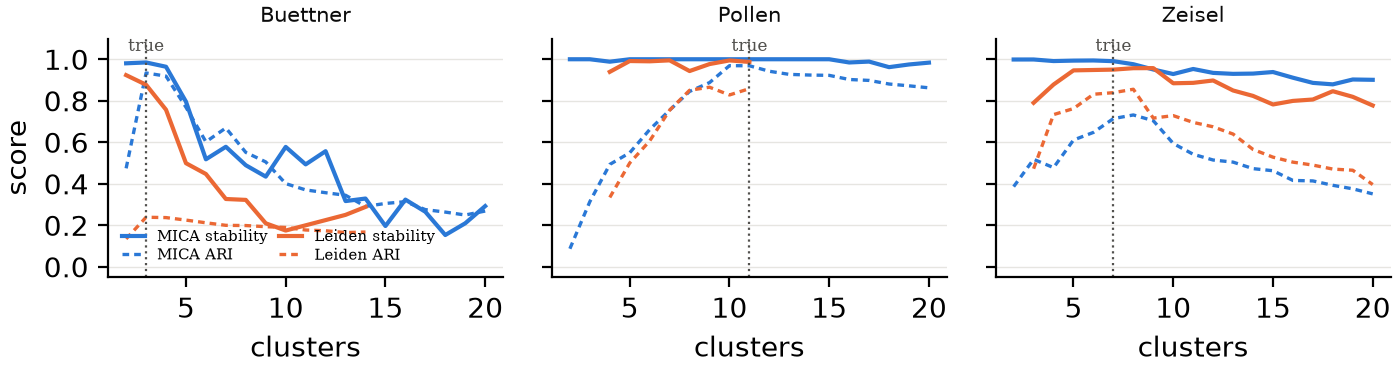

In [6]:
display(Image(filename=str(REPO / "latex" / "figures" / "a3_stability_curve.png"), width=900))

## Table II. Graph quality and cost

MICA's HNSW search against a correlation shortlist rescored exactly. The downstream ARIs let the labels pick the resolution, since this compares graphs rather than selection rules.

In [7]:
print(json.dumps(nums.get("graph_cost", {}), indent=1))

{
 "paper_pbmc14k/mica_hnsw": {
  "seconds_build_with_load": 429.8,
  "peak_rss_gb": 1.16,
  "recall": 0.9732,
  "seconds_downstream_median": 359.65,
  "ari": [
   0.8518509665203775,
   0.8519701124318079
  ],
  "ami": [
   0.8701401608615195,
   0.8716502867744532
  ],
  "seconds_candidates": null
 },
 "paper_pbmc14k/corr800": {
  "seconds_build_with_load": 17.9,
  "peak_rss_gb": 3.64,
  "recall": 0.9735,
  "seconds_downstream_median": 363.55,
  "ari": [
   0.8525219538306585,
   0.8526784895020296
  ],
  "ami": [
   0.8729055605546393,
   0.8748769419730086
  ],
  "seconds_candidates": 3.8
 },
 "allen_100k/mica_hnsw": {
  "seconds_build_with_load": 13634.7,
  "peak_rss_gb": 21.64,
  "recall": 0.9028,
  "seconds_downstream_median": 3974.95,
  "ari": [
   0.6408486865555603,
   0.6174242988808712
  ],
  "ami": [
   0.834561983125284,
   0.8308165265960182
  ],
  "seconds_candidates": null
 },
 "allen_100k/corr3200": {
  "seconds_build_with_load": 6224.2,
  "peak_rss_gb": 80.08,
  "rec

## MICA's shipped default against this benchmark's cluster counts

In [8]:
print(json.dumps(nums.get("mica_default", {}), indent=1))
print("true cluster counts:", sorted(nums["true_k"].values()))

{
 "shipped_k": 4,
 "source": "MICA/mica_mds.py, -nck default",
 "median_true_k_of_benchmark": 4,
 "datasets_with_true_k_4": [
  "chung",
  "usoskin",
  "klein"
 ],
 "mean_ari_true_k_3_to_5": 0.802,
 "mean_ari_true_k_outside": 0.579,
 "n_near": 6,
 "n_far": 3
}
true cluster counts: [3, 3, 4, 4, 4, 5, 7, 7, 8, 11]
